# 항공사 승객 만족 여부의 관련 요인 분석
### 기술통계·Spearman 상관분석과 다중 로지스틱 회귀
**고급빅데이터분석실무 · AI 빅데이터 전공 · 황태하**

## 연구 질문과 분석 목적
승객 특성과 비행 이용 정보를 고려했을 때, 어떤 서비스 평가가 전체 만족 여부와 어떻게 관련되는가?

이 분석의 중심은 **변수 사이의 관계와 회귀분석 결과를 설명하는 것**이다. 서비스 항목 간 상관을 확인한 뒤, 다른 포함 변수를 고려한 서비스별 오즈비와 95% 신뢰구간을 해석한다. 관찰자료의 조건부 관련성을 분석하므로 인과효과나 확정적인 투자 우선순위를 제시하지 않는다.

## 목차
1. 데이터 소개와 변수 구성
2. 데이터 품질과 분석 대상
3. 기술통계·탐색적 분석 결과
4. Spearman 상관분석 결과
5. 다중 로지스틱 회귀분석 설정과 결과
6. 회귀 진단과 민감도 분석
7. 종합 결론과 한계
8. 부록: 모형 사양 비교와 예측 측면의 보조 검증·재현 정보

## 1. 데이터 소개와 변수 구성
### 1.1 어떤 데이터인가?
본 분석에는 Kaggle에 공개된 **Airline Passenger Satisfaction** 데이터셋을 사용한다. 항공사 승객의 만족도 설문 응답과 승객 특성·비행 이용 정보를 함께 담은 표 형식의 공개 자료다. **한 행은 승객별 설문 응답 한 건**을 나타내며, 한 열은 성별·나이·서비스 평가 등 하나의 항목을 나타낸다. 제공된 두 파일은 같은 열 구조를 가지며, `train.csv` 103,904행과 `test.csv` 25,976행을 합해 총 **129,880행·25열**이다.

출처 설명에는 특정 항공사명, 조사 수행 주체, 조사 시점과 표집 절차가 충분히 제시되지 않는다. 따라서 '특정 항공사가 자사 승객 전체를 대상으로 실시한 조사'라고 단정하지 않는다. 제공 ID가 서로 다르다는 것만으로 동일 승객의 반복 탑승 여부까지 확인할 수는 없다. 출처는 분류 목적에 맞게 정리한 자료라고 설명한다.

- 출처: [Kaggle, teejmahal20, Airline Passenger Satisfaction](https://www.kaggle.com/datasets/teejmahal20/airline-passenger-satisfaction)
- 자료를 선택한 이유: 서비스 평가, 승객·비행 특성, 전체 만족 응답이 함께 있어 **상관분석과 조건부 관련성에 대한 회귀분석**을 연결할 수 있다.

### 1.2 변수는 어떻게 구성되어 있는가?
설명변수는 다음 세 묶음으로 구분한다. 이는 데이터 소개를 위한 내용상 분류이며, 요인분석으로 추출한 잠재요인이 아니다.

| 구분 | 원자료 열 | 의미·값 |
|---|---|---|
| 승객 특성 (3개) | `Gender`, `Age`, `Customer Type` | 성별, 나이, 충성 고객/비충성 고객 분류. 고객 분류를 신규/기존 고객으로 바꾸어 해석하지 않음 |
| 비행 이용 정보 (5개) | `Type of Travel`, `Class`, `Flight Distance`, `Departure Delay in Minutes`, `Arrival Delay in Minutes` | 여행 목적(업무/개인), 좌석 등급(Business/Eco/Eco Plus), 비행거리, 출발·도착 지연시간(분) |
| 서비스 만족도 문항 (14개) | 와이파이, 시간 편의, 예약, 탑승구, 기내식, 온라인 탑승수속, 좌석 등 | 항목별 1~5점 평가. 일부 0값의 의미와 처리는 아래에서 별도 검토 |
| 전체 만족 응답 (1개) | `satisfaction` | `satisfied` / `neutral or dissatisfied` |
| 식별·저장 정보 (2개) | `id`, `Unnamed: 0` | 응답 식별자와 CSV 저장 인덱스. 회귀 설명변수로 사용하지 않음 |

**서비스 문항 전체**

| 원자료 열 | 본 분석의 한글 표기 |
|---|---|
| Inflight wifi service | 기내 와이파이 |
| Departure/Arrival time convenient | 출도착 시간 편의 |
| Ease of Online booking | 온라인 예약 편의 |
| Gate location | 탑승구 위치 |
| Food and drink | 기내식·음료 |
| Online boarding | 온라인 탑승수속 |
| Seat comfort | 좌석 편안함 |
| Inflight entertainment | 기내 엔터테인먼트 |
| On-board service | 기내 응대 |
| Leg room service | 다리 공간 |
| Baggage handling | 수하물 처리 |
| Checkin service | 체크인 서비스 |
| Inflight service | 기내 서비스 |
| Cleanliness | 청결도 |

### 1.3 무엇을 설명하는가?
전체 만족 응답 `satisfaction`을 **만족=1, 중립 또는 불만족=0**으로 코딩한다. 중립과 불만족을 원자료에서 분리할 수 없으므로 0을 불만족만으로 부르지 않는다. 서비스별 점수는 설명변수이고 전체 만족 응답은 결과변수다. 서비스 3점은 회귀의 기준 범주이며 전체 만족 응답의 중립과 같은 뜻이 아니다.

### 1.4 활용 기법과 역할
| 기법 | 확인할 질문 | 핵심 결과 |
|---|---|---|
| 기술통계·탐색적 분석 | 표본은 어떻게 구성되며 집단별 만족 비율은 다른가? | 표본 수, 결측·0값, 집단별 비율·95% CI |
| Spearman 상관분석 | 순서형 서비스 평가 항목들은 서로 얼마나 관련되는가? | 상관계수·상관행렬 |
| **다중 로지스틱 회귀분석** | 승객·비행 정보와 다른 서비스를 고려해도 관련성이 남는가? | **조정 오즈비·95% CI·관련 방향** |
| 회귀 진단·민감도 검토 | 추정과 해석이 자료·사양 선택에 얼마나 민감한가? | 공선성·영향력·관련 방향 변화 |

요인분석·신뢰도분석·분산분석은 이번 연구 질문에 필수적이지 않아 포함하지 않는다. 예측 성능 평가는 부록의 보조 검증으로 구분한다.

### 1.5 실행 안내
VS Code에서 Python 커널을 선택해 위에서 아래로 실행한다. CSV는 노트북과 같은 폴더 또는 `data`, `source`, `upload`, 상위 `source` 폴더에 둔다. `train(1).csv`, `test(1).csv`도 자동 탐색한다. 제공된 `train` 파일을 **기준 분석 자료**, `test` 파일을 **보조 예측 검증 자료**로 사용해 기존 분석 결과와의 일관성을 유지한다. 본문의 결론은 회귀계수와 관계 해석에 두며, 정확도 수치는 부록에서 확인한다.

In [1]:
# 최초 실행 시 필요한 패키지를 설치한다. 이미 설치되어 있으면 생략 가능하다.
# %pip install pandas numpy scipy statsmodels scikit-learn matplotlib seaborn
import sys, platform, importlib.metadata, warnings, json, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import stats
from scipy.special import expit
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint
from sklearn.model_selection import train_test_split
from sklearn.metrics import (roc_auc_score, accuracy_score, precision_score,
    recall_score, f1_score, brier_score_loss, log_loss, confusion_matrix, roc_curve)
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt
from matplotlib import font_manager
import seaborn as sns
from IPython.display import display
SEED = 20261029
pd.set_option('display.max_columns', 12)
pd.set_option('display.max_rows', 100)
sns.set_theme(style='whitegrid', palette=['#087F8C','#23395B','#D58B38'])
font_path=Path('/usr/local/share/fonts/NotoSansCJKkr-Regular.otf')
if font_path.exists(): font_manager.fontManager.addfont(str(font_path))
available={f.name for f in font_manager.fontManager.ttflist}
font=next((f for f in ['Malgun Gothic','AppleGothic','Noto Sans CJK KR','NanumGothic'] if f in available),'DejaVu Sans')
plt.rcParams.update({'font.family':font,'axes.unicode_minus':False,'figure.dpi':120})
print('Python:',platform.python_version(),' / seed:',SEED)
versions={x:importlib.metadata.version(x) for x in ['pandas','numpy','scipy','statsmodels','scikit-learn','matplotlib','seaborn']}
display(pd.Series(versions,name='version').to_frame())

Python: 3.12.14  / seed: 20261029


,version
pandas,2.2.3
numpy,2.3.5
scipy,1.17.0
statsmodels,0.15.0
scikit-learn,1.8.0
matplotlib,3.10.8
seaborn,0.13.2


In [2]:
def locate_csv(stem):
    roots=[Path.cwd(),Path.cwd()/'data',Path.cwd()/'source',Path.cwd()/'upload',Path.cwd().parent/'source',Path.cwd().parent/'upload']
    for folder in roots:
        for name in [f'{stem}.csv', f'{stem}(1).csv']:
            p=folder/name
            if p.is_file(): return p
    raise FileNotFoundError(f'{stem}.csv를 노트북 폴더 또는 data/source/upload 폴더에 두세요.')
paths={name:locate_csv(name) for name in ['train','test']}
raw_train=pd.read_csv(paths['train'])
raw_test=pd.read_csv(paths['test'])
source_hashes={k:hashlib.sha256(p.read_bytes()).hexdigest() for k,p in paths.items()}
print('파일 크기:',raw_train.shape,raw_test.shape)
print('파일 경로:',{k:str(v) for k,v in paths.items()})
SERVICES=['Inflight wifi service','Departure/Arrival time convenient','Ease of Online booking',
          'Gate location','Food and drink','Online boarding','Seat comfort','Inflight entertainment',
          'On-board service','Leg room service','Baggage handling','Checkin service','Inflight service','Cleanliness']
KOREAN=['기내 와이파이','출도착 시간 편의','온라인 예약 편의','탑승구 위치','기내식·음료','온라인 탑승수속','좌석 편안함','기내 엔터테인먼트','기내 응대','다리 공간','수하물 처리','체크인 서비스','기내 서비스','청결도']
SKEYS=[f's{i:02d}' for i in range(1,15)]
labels=dict(zip(SKEYS,KOREAN))
rename=dict(zip(SERVICES,SKEYS))
rename.update({'Gender':'gender','Customer Type':'customer','Age':'age','Type of Travel':'travel',
 'Class':'cabin','Flight Distance':'distance','Arrival Delay in Minutes':'arrival','Departure Delay in Minutes':'departure'})
assert raw_train.columns.tolist()==raw_test.columns.tolist()
assert set(raw_train.satisfaction)=={'satisfied','neutral or dissatisfied'}
assert all(raw_train[c].between(0,5).all() and raw_test[c].between(0,5).all() for c in SERVICES)
assert not raw_train.id.duplicated().any() and not raw_test.id.duplicated().any()
assert not set(raw_train.id).intersection(raw_test.id)
assert raw_train.shape==(103904,25) and raw_test.shape==(25976,25)
audit=pd.DataFrame({'학습 결측':raw_train.isna().sum(),'테스트 결측':raw_test.isna().sum()})
display(audit.loc[(audit>0).any(axis=1)])
zero_table=pd.DataFrame({'항목':KOREAN,'학습 0값':raw_train[SERVICES].eq(0).sum().values,
 '테스트 0값':raw_test[SERVICES].eq(0).sum().values})
display(zero_table)

파일 크기: (103904, 25) (25976, 25)
파일 경로: {'train': '/workspace/scratch/0d22ee6007fc/upload/train(1).csv', 'test': '/workspace/scratch/0d22ee6007fc/upload/test(1).csv'}


,학습 결측,테스트 결측
Arrival Delay in Minutes,310,83


,항목,학습 0값,테스트 0값
0,기내 와이파이,3103,813
1,출도착 시간 편의,5300,1381
2,온라인 예약 편의,4487,1195
3,탑승구 위치,1,0
4,기내식·음료,107,25
5,온라인 탑승수속,2428,652
6,좌석 편안함,1,0
7,기내 엔터테인먼트,14,4
8,기내 응대,3,2
9,다리 공간,472,126


## 2. 데이터 품질과 분석 대상
**0값을 점수 0으로 회귀식에 넣지 않는다.** Kaggle 설명은 와이파이의 0을 `Not Applicable`로 명시한다. 다른 서비스 항목의 0은 의미 설명이 충분하지 않으므로 최저 평가로 단정하지 않는다. 주 분석에서는 모든 서비스가 1~5점인 응답만 사용한다. 이는 결측이 무작위라는 가정 없이 분석 대상을 명확히 하는 선택이며, 전체 승객으로 일반화할 때 선택 편향의 한계가 있다.

도착 지연시간의 실제 결측은 기준 분석 자료(train) 중앙값으로 대체하고 결측 여부를 별도로 포함한다. 0분 지연은 그대로 유지한다. 출발·도착 지연의 정보 중복을 고려해 도착 지연만 회귀식에 포함한다. 모든 대체값과 기준은 기준 분석 자료(train)에서 정한다.

보조 검증 파일(test)은 과거 미니 과제에서 탐색된 이력이 있으므로 완전히 새로운 외부 검증 자료로 부르지 않는다. 이번 모형 선택에는 테스트 성능을 사용하지 않으며, 제공된 분할에 따른 보류 자료 평가로 해석한다.

In [3]:
def prepare(raw):
    d=raw.rename(columns=rename).copy()
    d['y']=d['satisfaction'].eq('satisfied').astype(int)
    return d
train_all=prepare(raw_train)
test_all=prepare(raw_test)
keep_train=train_all[SKEYS].ge(1).all(axis=1)
keep_test=test_all[SKEYS].ge(1).all(axis=1)
train=train_all.loc[keep_train].copy()
test=test_all.loc[keep_test].copy()
flow=pd.DataFrame([
 {'자료':name,'전체':len(all_d),'서비스 1~5점 분석 대상':int(keep.sum()),'제외':int((~keep).sum()),
  '전체 만족률':all_d.y.mean(),'포함 만족률':all_d.loc[keep,'y'].mean(),'제외 만족률':all_d.loc[~keep,'y'].mean()}
 for name,all_d,keep in [('학습',train_all,keep_train),('테스트',test_all,keep_test)]
])
display(flow)
selection=train_all.assign(included=keep_train).groupby('included').agg(n=('y','size'),satisfied=('y','mean'),
 age=('age','mean'),business_travel=('travel',lambda x:x.eq('Business travel').mean()),
 business_class=('cabin',lambda x:x.eq('Business').mean()))
display(selection)
print('출발·도착 지연 Pearson r (학습):',train_all[['departure','arrival']].corr().iloc[0,1])

출발·도착 지연 Pearson r (학습): 0.9654809013755764


,자료,전체,서비스 1~5점 분석 대상,제외,전체 만족률,포함 만족률,제외 만족률
0,학습,103904,95704,8200,0.433333,0.425865,0.520488
1,테스트,25976,23863,2113,0.438982,0.430499,0.534785


,n,satisfied,age,business_travel,business_class
included,,,,,
False,8200,0.520488,34.326585,0.676707,0.390366
True,95704,0.425865,39.812662,0.690734,0.485497


### 분석 대상과 제외에 대한 해석
기준 분석 자료(train) **103,904건 중 95,704건**을 주 분석에 사용하고 8,200건(7.89%)을 제외했다. 포함 집단 만족률은 **42.59%**, 제외 집단은 **52.05%**이다. 제외 집단은 평균 나이와 좌석 등급 구성도 다르므로 0값 제외를 무작위 표본 손실로 보지 않는다. 보조 검증 자료(test)의 같은 조건 대상은 **23,863건**이다. 출발·도착 지연의 상관은 약 0.965로 높아 도착 지연만 포함했다. 중앙값 대체와 결측 표시의 계수는 결측이 무작위임을 입증하지 않는다.

## 3. 기술통계·탐색적 분석 결과
먼저 여행 목적·좌석 등급·고객 유형별 표본 수와 만족 비율을 확인한다. 비율의 불확실성은 Wilson 95% 신뢰구간으로 표시한다. 이 단계는 각 집단에서 관찰된 현황을 보여주는 **조정 전 비교**이며, 집단 간 차이를 독립적인 영향이나 인과효과로 해석하지 않는다.

travel
cabin
customer


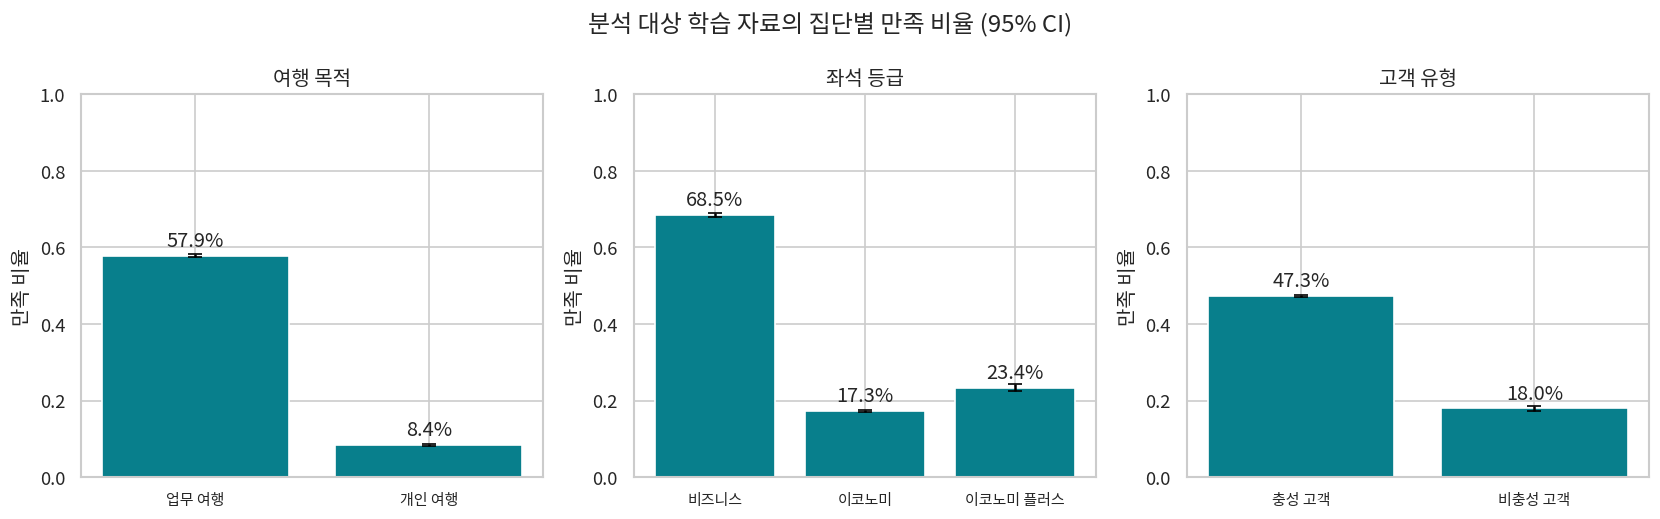

,count,sum,mean,lo,hi
travel,,,,,
Business travel,66106,38268,0.5789,0.5751,0.5826
Personal Travel,29598,2489,0.0841,0.0810,0.0873


,count,sum,mean,lo,hi
cabin,,,,,
Business,46464,31824,0.6849,0.6807,0.6891
Eco,42241,7295,0.1727,0.1691,0.1763
Eco Plus,6999,1638,0.2340,0.2243,0.2441


,count,sum,mean,lo,hi
customer,,,,,
Loyal Customer,80319,37993,0.4730,0.4696,0.4765
disloyal Customer,15385,2764,0.1797,0.1737,0.1858


In [4]:
def group_rates(d,col):
    t=d.groupby(col,observed=True).y.agg(['count','sum','mean'])
    t['lo'],t['hi']=proportion_confint(t['sum'],t['count'],method='wilson')
    return t
rates={c:group_rates(train,c) for c in ['travel','cabin','customer']}
fig,axs=plt.subplots(1,3,figsize=(14,4.4))
maps={'Business travel':'업무 여행','Personal Travel':'개인 여행','Business':'비즈니스','Eco':'이코노미','Eco Plus':'이코노미 플러스','Loyal Customer':'충성 고객','disloyal Customer':'비충성 고객'}
for ax,(col,t) in zip(axs,rates.items()):
    ax.bar([maps.get(x,x) for x in t.index],t['mean'],color='#087F8C',
     yerr=[t['mean']-t.lo,t.hi-t['mean']],capsize=4)
    ax.set_ylim(0,1);ax.set_ylabel('만족 비율');ax.set_title({'travel':'여행 목적','cabin':'좌석 등급','customer':'고객 유형'}[col]);ax.tick_params(axis='x',labelsize=9)
    for i,v in enumerate(t['mean']):ax.text(i,v+.025,f'{v:.1%}',ha='center')
plt.suptitle('분석 대상 학습 자료의 집단별 만족 비율 (95% CI)');plt.tight_layout();plt.show()
for col,t in rates.items(): print(col);display(t.round(4))

### 기술통계 결과 해석
업무 여행 집단의 만족 비율은 **57.9%**, 개인 여행 집단은 **8.4%**였다. 좌석 등급별로는 비즈니스 **68.5%**, 이코노미 **17.3%**, 이코노미 플러스 **23.4%**였다. 충성 고객 집단의 만족 비율은 **47.3%**, 비충성 고객 집단은 **18.0%**였다. 모두 기준 분석 대상 95,704건에서 계산한 값이다.

그래프는 만족 비율과 95% CI를 보여준다. 큰 표본으로 구간이 좁더라도 표집 대표성까지 입증되는 것은 아니다. 집단마다 여행 목적·서비스 경험 등이 함께 다를 수 있으므로, 뒤의 회귀분석에서 이러한 조건을 함께 고려한다.

## 4. Spearman 상관분석 결과
서비스 평가는 1~5점의 순서형 변수이므로 **Spearman 순위상관계수(ρ)**를 사용한다. ρ는 두 항목의 평가 순위가 함께 높아지거나 낮아지는 경향을 나타낸다. 양의 값은 같은 방향의 단조 관계이며, 절댓값이 클수록 그 경향이 강하다. 인과 방향이나 두 문항이 같은 잠재개념을 측정한다는 사실을 증명하지는 않는다.

서비스 간 관련성을 탐색하고 회귀계수 해석에 필요한 정보 중복을 확인한다. 상관이 높다는 이유만으로 문항을 자동 제거하지 않고 회귀 진단과 함께 판단한다.

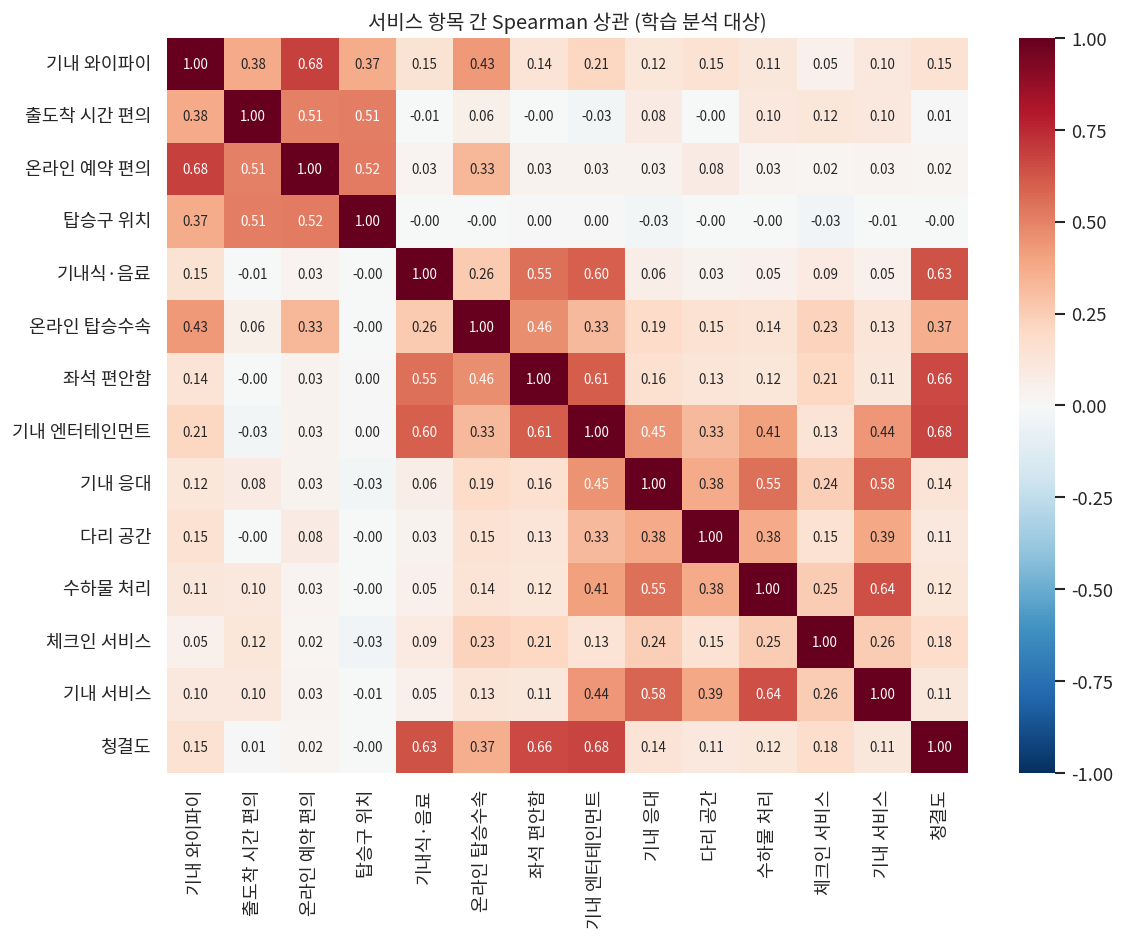

,a,b,rho,abs_r
1,기내 와이파이,온라인 예약 편의,0.680257,0.680257
75,기내 엔터테인먼트,청결도,0.675017,0.675017
69,좌석 편안함,청결도,0.663222,0.663222
86,수하물 처리,기내 서비스,0.644034,0.644034
54,기내식·음료,청결도,0.634931,0.634931
63,좌석 편안함,기내 엔터테인먼트,0.605345,0.605345
48,기내식·음료,기내 엔터테인먼트,0.599493,0.599493
79,기내 응대,기내 서비스,0.580010,0.580010
47,기내식·음료,좌석 편안함,0.550911,0.550911
77,기내 응대,수하물 처리,0.549817,0.549817


In [5]:
corr=train[SKEYS].corr(method='spearman')
fig,ax=plt.subplots(figsize=(10,8))
sns.heatmap(corr.rename(index=labels,columns=labels),ax=ax,cmap='RdBu_r',vmin=-1,vmax=1,annot=True,fmt='.2f',annot_kws={'size':8})
ax.set_title('서비스 항목 간 Spearman 상관 (학습 분석 대상)');plt.tight_layout();plt.show()
corr_pairs=[{'a':labels[a],'b':labels[b],'rho':float(corr.loc[a,b])} for i,a in enumerate(SKEYS) for b in SKEYS[i+1:]]
display(pd.DataFrame(corr_pairs).assign(abs_r=lambda x:x.rho.abs()).sort_values('abs_r',ascending=False).head(10))

### 상관분석 결과와 히트맵 해석
와이파이–온라인 예약 편의의 상관은 **ρ=0.680**, 엔터테인먼트–청결도는 **ρ=0.675**, 좌석 편안함–청결도는 **ρ=0.663**이었다. 이 자료에서 해당 항목들을 함께 높게 또는 낮게 평가하는 경향이 관찰된다.

히트맵의 대각선은 자기 자신과의 상관 1이며, 붉은색이 진한 항목 쌍일수록 양의 상관이 크다. 이 결과를 바탕으로 서비스 평가가 서로 독립적이지 않다는 점을 고려한다. 회귀분석에서는 다른 서비스 평가도 함께 포함하므로, 단순 비교와 조정 후 관련 방향이 달라질 수 있다. 특정 항목이 다른 항목을 높인다고 해석하지 않는다.

## 5. 다중 로지스틱 회귀분석 설정과 결과
### 5.1 이 분석을 선택한 이유
결과변수가 만족/중립 또는 불만족의 두 범주이므로 **이항 다중 로지스틱 회귀**를 사용한다. 목적은 다른 포함 변수를 고려한 서비스별 관련 방향과 크기를 추정하는 것이다.

$$\log\frac{P(Y=1\mid X)}{1-P(Y=1\mid X)}=\beta_0+\sum_j\beta_jX_j$$

서비스 14개는 각각 **범주형**으로 입력한다. 1점 증가가 언제나 동일한 로그오즈 차이를 만든다는 가정을 피하고, **3점을 기준으로 1·2·4·5점**을 비교한다. 주된 요약은 같은 대비인 **5점 대 3점**이다. 이 사양은 이전 분석의 기준 자료 내부 비교에서도 점수형 사양보다 작은 검증 오차를 보였으며, 그 상세 비교는 부록에 배치한다. 이후의 추론은 이 선택을 조건으로 한 탐색적 결과다.

공통 조정변수는 **성별, 고객 유형, 여행 목적, 좌석 등급, 나이와 제곱항, 비행거리와 제곱항, log(1+도착 지연분), 도착 지연 결측 표시**다. 나이는 `(나이−40)/10`, 거리는 `(거리−1200)/1000`으로 중심화·척도 변환한다. 거리의 원 단위가 명확히 확인되지 않아 km로 단정하지 않는다. 제곱항은 나이·거리에 단순 직선 관계를 강제하지 않기 위해 포함한다.

HC0 표준오차로 개별 95% 신뢰구간을 계산한다. 5점 대 3점의 14개 대비에는 BH 방식의 FDR 보정 q값도 제시한다. 구간은 동시 신뢰구간이 아니며 모형 선택의 불확실성까지 반영하지 않는다. 오즈비는 조건부 관련성으로, 확률 배수나 인과효과가 아니다.

In [6]:
BASE="C(gender, Treatment(reference='Female')) + C(customer, Treatment(reference='Loyal Customer')) + C(travel, Treatment(reference='Business travel')) + C(cabin, Treatment(reference='Business')) + age10 + age10_sq + dist1000 + dist1000_sq + arrival_log + arrival_missing"
SCORE=' + '.join(SKEYS)
CAT=' + '.join(f'C({s}, Treatment(reference=3))' for s in SKEYS)
FORMULAS={'M0':'y ~ '+BASE,'M1':'y ~ '+BASE+' + '+SCORE,'M2':'y ~ '+BASE+' + '+CAT}
def features(d,arrival_median):
    x=d.copy()
    x['age10']=(x.age-40)/10;x['age10_sq']=x.age10**2
    x['dist1000']=(x.distance-1200)/1000;x['dist1000_sq']=x.dist1000**2
    x['arrival_missing']=x.arrival.isna().astype(int)
    x['arrival_log']=np.log1p(x.arrival.fillna(arrival_median))
    return x
def fit_glm(formula,d,robust=False):
    return smf.glm(formula,data=d,family=sm.families.Binomial()).fit(maxiter=100,cov_type='HC0' if robust else 'nonrobust')
def metrics(y,p):
    pred=(p>=.5).astype(int)
    return {'AUC':roc_auc_score(y,p),'accuracy':accuracy_score(y,pred),
      'precision':precision_score(y,pred,zero_division=0),'recall':recall_score(y,pred),
      'F1':f1_score(y,pred),'Brier':brier_score_loss(y,p),'logloss':log_loss(y,p)}

# 본문의 주 사양: 서비스별 범주형 다중 로지스틱 회귀
chosen='M2'

,beta,se_HC0,p,OR,CI_low,CI_high
Intercept,-1.8658,0.0738,<0.001,0.1548,0.1339,0.1789
"C(gender, Treatment(reference='Female'))[T.Male]",0.0479,0.0276,0.0827,1.0490,0.9938,1.1073
"C(customer, Treatment(reference='Loyal Customer'))[T.disloyal Customer]",-3.4627,0.0546,<0.001,0.0313,0.0282,0.0349
"C(travel, Treatment(reference='Business travel'))[T.Personal Travel]",-4.2817,0.0692,<0.001,0.0138,0.0121,0.0158
"C(cabin, Treatment(reference='Business'))[T.Eco]",-0.5446,0.0402,<0.001,0.5801,0.5361,0.6277
"C(cabin, Treatment(reference='Business'))[T.Eco Plus]",-0.7302,0.0643,<0.001,0.4818,0.4248,0.5465
"C(s01, Treatment(reference=3))[T.1]",0.3907,0.0575,<0.001,1.4780,1.3205,1.6544
"C(s01, Treatment(reference=3))[T.2]",0.0380,0.0492,0.4399,1.0387,0.9432,1.1439
"C(s01, Treatment(reference=3))[T.4]",1.4209,0.0509,<0.001,4.1410,3.7481,4.5752
"C(s01, Treatment(reference=3))[T.5]",6.8433,0.2000,<0.001,937.5893,633.5428,1387.5522


,key,서비스,OR_5_vs_3,CI_low,CI_high,p_5_vs_3,joint_p,q_BH
0,s01,기내 와이파이,937.5893,633.5383,1387.5622,<0.001,<0.001,<0.001
5,s06,온라인 탑승수속,18.7370,16.9171,20.7528,<0.001,<0.001,<0.001
6,s07,좌석 편안함,4.8302,4.3285,5.3901,<0.001,<0.001,<0.001
12,s13,기내 서비스,4.2450,3.7440,4.8131,<0.001,<0.001,<0.001
10,s11,수하물 처리,4.0590,3.6270,4.5424,<0.001,<0.001,<0.001
9,s10,다리 공간,2.4719,2.2500,2.7158,<0.001,<0.001,<0.001
11,s12,체크인 서비스,2.0955,1.9300,2.2752,<0.001,<0.001,<0.001
8,s09,기내 응대,1.8485,1.6653,2.0519,<0.001,<0.001,<0.001
13,s14,청결도,1.6243,1.4621,1.8045,<0.001,<0.001,<0.001
2,s03,온라인 예약 편의,1.4135,1.2049,1.6582,<0.001,<0.001,<0.001


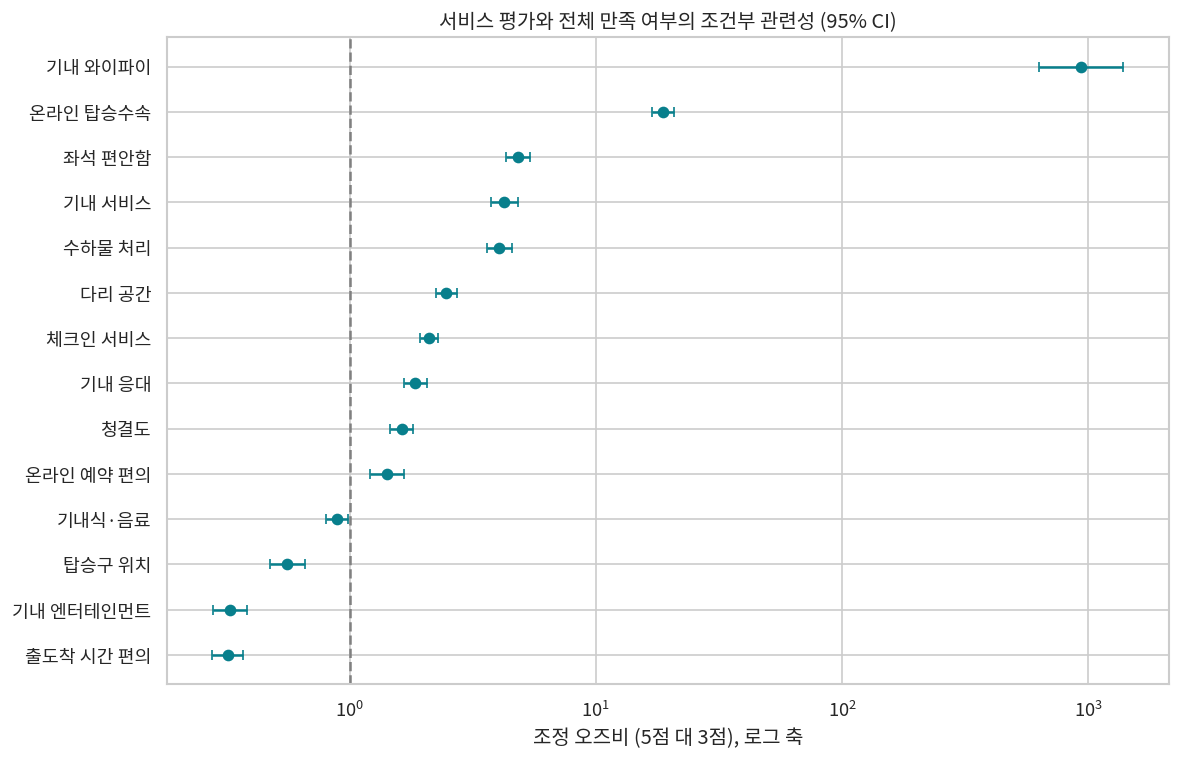

In [7]:
arrival_median=float(train.arrival.median())
tr=features(train,arrival_median)
final_models={'M2':fit_glm(FORMULAS['M2'],tr,robust=True)}
model=final_models[chosen]
assert all(m.converged for m in final_models.values())
assert np.isfinite(model.params).all() and np.isfinite(model.bse).all()
full_coef=pd.DataFrame({'beta':model.params,'se_HC0':model.bse,'p':model.pvalues,
 'OR':np.exp(model.params),'CI_low':np.exp(model.conf_int()[0]),'CI_high':np.exp(model.conf_int()[1])})
display(full_coef.assign(p=full_coef.p.map(lambda v: '<0.001' if v<.001 else f'{v:.4f}')).round(4))
contrasts=[]
for s in SKEYS:
    term=f'C({s}, Treatment(reference=3))[T.5]' if chosen=='M2' else s
    delta=1 if chosen=='M2' else 2
    beta=float(model.params[term])*delta;se=float(model.bse[term])*delta
    indices=[i for i,t in enumerate(model.params.index) if t.startswith(f'C({s},') or t==s]
    R=np.eye(len(model.params))[indices]
    w=model.wald_test(R,scalar=True)
    contrasts.append({'key':s,'서비스':labels[s],'OR_5_vs_3':np.exp(beta),
      'CI_low':np.exp(beta-1.96*se),'CI_high':np.exp(beta+1.96*se),
      'p_5_vs_3':float(2*stats.norm.sf(abs(beta/se))),'joint_p':float(w.pvalue)})
contrast=pd.DataFrame(contrasts)
contrast['q_BH']=multipletests(contrast.p_5_vs_3,method='fdr_bh')[1]
contrast=contrast.sort_values('OR_5_vs_3',ascending=False)
display(contrast.assign(**{c:contrast[c].map(lambda v:'<0.001' if v<.001 else f'{v:.4f}') for c in ['p_5_vs_3','joint_p','q_BH']}).round(4))
fig,ax=plt.subplots(figsize=(10,6.5))
t=contrast.iloc[::-1]
ax.errorbar(t.OR_5_vs_3,np.arange(len(t)),xerr=[t.OR_5_vs_3-t.CI_low,t.CI_high-t.OR_5_vs_3],fmt='o',color='#087F8C',capsize=3)
ax.set_yticks(np.arange(len(t)),t['서비스']);ax.set_xscale('log');ax.axvline(1,ls='--',color='gray')
ax.set_xlabel('조정 오즈비 (5점 대 3점), 로그 축');ax.set_title('서비스 평가와 전체 만족 여부의 조건부 관련성 (95% CI)')
plt.tight_layout();plt.show()

### 회귀계수와 그래프 해석
- 온라인 탑승수속 5점의 만족 오즈는 3점 대비 **18.74배**(95% CI 16.92–20.75)이다. 다른 포함 변수는 일정하다는 조건이며, 만족 확률이 그 배수로 증가하거나 실제 개선 시 동일 효과가 난다는 뜻은 아니다.
- 와이파이 대비는 **OR 937.59**(95% CI 633.54–1387.56)로 매우 크다. 같은 자료의 응답 집중과 조건부 중첩 문제를 아래 추가 진단에서 확인한다.
- 엔터테인먼트는 **OR 0.327**로 역방향이다. 다른 서비스와의 상관 및 조정 조건을 고려한 관련성으로, 서비스를 줄이라는 결론을 내릴 수 없다. 단순 OR와 조정 OR를 아래에서 비교한다.
- 숲그림의 축은 로그 축이고 OR=1이 무관 기준이다. 14개 대비의 BH q값은 모두 0.05 미만이지만 중요도나 인과성을 보장하지 않는다.
- **추론은 탐색적이며 선택된 모형 사양을 조건으로 한다.** 명목 CI와 BH 보정은 같은 학습 자료에서 M1/M2를 선택한 불확실성까지 반영하지 않는다.

### 5.2 결과를 읽는 순서
1. **비교 조건:** 다른 서비스 평가와 승객·비행 이용 정보를 함께 고려한 5점 대 3점 비교다.
2. **크기와 구간:** 온라인 탑승수속 OR 18.74(95% CI 16.92–20.75)는 5점 응답의 만족 **오즈**가 3점보다 큰 관련성을 뜻한다. 만족 확률이 18.74배라는 의미는 아니다.
3. **방향:** OR>1은 기준보다 높은 만족 오즈, OR<1은 낮은 만족 오즈다. 엔터테인먼트 OR 0.327처럼 직관과 다른 값도 숨기지 않고 조건부 비교와 민감도에서 점검한다.
4. **유의성의 범위:** 14개 대비의 q값은 0.05 미만이지만 큰 표본에서는 작은 차이도 유의해질 수 있다. 유의한 변수만으로 중요도나 투자 순위를 확정하지 않는다.
5. **조정변수의 주의점:** 나이와 거리는 제곱항도 포함해 선형항 OR 하나로 전 범위의 증가 효과를 설명하지 않는다. 고객 유형은 제공된 충성/비충성 분류를 그대로 사용한다.

## 6. 회귀 진단과 민감도 분석
### 6.1 공선성과 영향력 진단
회귀계수 해석에 앞서 설계행렬의 순위, 수렴, 계수·표준오차의 유한성, 개별 더미 VIF와 영향력 지표를 점검한다. 상관이 있다는 사실과 추정 불가능할 정도의 완전한 공선성은 구별한다. 범주형 변수의 개별 더미 VIF는 변수 전체의 GVIF와 다르다.

In [8]:
# 모든 설명변수 더미를 포함한 설계행렬 점검. 범주형 변수의 개별 더미 VIF는 참고값이다.
X=model.model.exog
names=model.model.exog_names
sd=X[:,1:].std(axis=0)
assert (sd>0).all()
R=np.corrcoef(X[:,1:],rowvar=False)
assert np.linalg.matrix_rank(X)==X.shape[1]
vif=pd.DataFrame({'term':names[1:],'VIF':np.diag(np.linalg.inv(R))}).sort_values('VIF',ascending=False)
condition=float(np.linalg.cond((X[:,1:]-X[:,1:].mean(axis=0))/sd))
display(vif.head(12).round(3));print('표준화 설계행렬 condition number:',round(condition,2))
influence=model.get_influence(observed=False)
max_cook=float(np.max(influence.cooks_distance[0]));max_hat=float(np.max(influence.hat_matrix_diag))
print('최대 Cook distance:',max_cook,'최대 leverage:',max_hat)
print('최대 |beta|:',float(model.params.abs().max()),'최대 표준오차:',float(model.bse.max()))

표준화 설계행렬 condition number: 9.2
최대 Cook distance: 0.0010889145601058036 최대 leverage: 0.025124689711597342
최대 |beta|: 6.843312038617525 최대 표준오차: 0.26610939415643964


,term,VIF
36,"C(s08, Treatment(reference=3))[T.5]",5.661
35,"C(s08, Treatment(reference=3))[T.4]",5.364
34,"C(s08, Treatment(reference=3))[T.2]",5.343
33,"C(s08, Treatment(reference=3))[T.1]",4.850
13,"C(s03, Treatment(reference=3))[T.1]",3.961
14,"C(s03, Treatment(reference=3))[T.2]",3.810
5,"C(s01, Treatment(reference=3))[T.1]",3.563
58,"C(s14, Treatment(reference=3))[T.2]",3.497
6,"C(s01, Treatment(reference=3))[T.2]",3.355
32,"C(s07, Treatment(reference=3))[T.5]",3.344


### 진단 결과의 해석
주 모형이 수렴하고 최종 설계행렬이 full rank이며, 계수와 표준오차는 유한하다. 범주별 더미 중 최대 VIF는 **5.66**, 표준화 설계행렬 condition number는 **9.20**이다. 최대 VIF는 엔터테인먼트 5점 더미에서 나타나므로 이 계수의 해석에는 항목 간 중복을 고려해야 한다. 범주형 전체 변수의 GVIF와 개별 더미 VIF는 다르며, 절대적 합격·탈락 기준 하나로 판단하지 않는다.

최대 Cook distance는 약 **0.0011**이고, 극단적인 회귀계수 하나를 자동 제거하지 않는다. 이러한 진단은 무조건적인 모형 타당성, 충분한 조건부 중첩, 독립성을 입증하지 않는다. 나이와 거리에 제곱항이 있어 선형항 하나의 OR를 전체 범위의 일정한 증가 효과로 읽지 않는다.

### 6.2 제외 대신 대체했을 때의 민감도
전체 자료에서 서비스 0을 미평가 표시로 보고, 각 항목의 학습 **유효점수 중앙값**으로 대체한다. 하나라도 0인 응답은 `any_zero=1`로 표시한다. 이는 0의 불명확한 의미를 해결하는 정답이 아니라, 행 삭제 선택에 얼마나 민감한지 확인하는 보조 사양이다. 주 분석 대상과 모집단이 달라 성능 차이를 순수한 모형 우열로 해석하지 않는다. 매우 드문 0에 항목별 더미를 각각 두면 추정이 불안정해질 수 있어 공통 표시 하나를 사용한다.

In [9]:
service_medians={s:int(train_all.loc[train_all[s]>0,s].median()) for s in SKEYS}
def fill_services(d):
    x=d.copy();x['any_zero']=x[SKEYS].eq(0).any(axis=1).astype(int)
    for s in SKEYS:x.loc[x[s]==0,s]=service_medians[s]
    return x
sens_tr=features(fill_services(train_all),train_all.arrival.median())
sens=fit_glm(FORMULAS[chosen]+' + any_zero',sens_tr,robust=True)
assert sens.converged
sens_rows=[]
for _,row in contrast.iterrows():
    s=row['key'];term=f'C({s}, Treatment(reference=3))[T.5]' if chosen=='M2' else s
    delta=1 if chosen=='M2' else 2
    b=float(sens.params[term])*delta;se=float(sens.bse[term])*delta
    sens_rows.append({'key':s,'서비스':labels[s],'主 OR':row['OR_5_vs_3'],'민감도 OR':np.exp(b),
      '민감도 CI_low':np.exp(b-1.96*se),'민감도 CI_high':np.exp(b+1.96*se),
      '방향 일치':(row['OR_5_vs_3']>1)==(b>0)})
sensitivity=pd.DataFrame(sens_rows)
display(sensitivity.round(4))

,key,서비스,主 OR,민감도 OR,민감도 CI_low,민감도 CI_high,방향 일치
0,s01,기내 와이파이,937.5893,438.7699,305.0604,631.0850,True
1,s06,온라인 탑승수속,18.7370,21.8418,19.9073,23.9643,True
2,s07,좌석 편안함,4.8302,4.0555,3.6704,4.4810,True
3,s13,기내 서비스,4.2450,3.5654,3.1933,3.9809,True
4,s11,수하물 처리,4.0590,3.6564,3.3075,4.0420,True
5,s10,다리 공간,2.4719,2.5615,2.3561,2.7847,True
6,s12,체크인 서비스,2.0955,1.8795,1.7495,2.0192,True
7,s09,기내 응대,1.8485,1.7093,1.5632,1.8690,True
8,s14,청결도,1.6243,1.5166,1.3763,1.6713,True
9,s03,온라인 예약 편의,1.4135,0.8343,0.7245,0.9608,False


### 전처리 민감도 해석
전체 자료 대체 사양에서 온라인 탑승수속 OR는 약 **21.84**, 좌석 편안함은 **4.06**으로 주 분석과 같은 방향이다. 와이파이는 **938에서 439 수준**으로 크기가 달라져 극단값의 모형·전처리 의존성을 보여준다.

특히 **온라인 예약 편의는 OR 1.413에서 0.834로 방향이 바뀌므로 관련성의 방향이 불안정하다.** 14개 중 13개 방향이 일치한다는 요약만으로 이를 숨기지 않는다. 이 비교는 분석 대상과 대체 방식이 함께 달라져 선택 편향이 작다는 증거가 되지 않는다. 전처리·대상 변경에 대한 관련성의 민감도를 확인하는 보조 사양이다.

### 6.3 극단적인 오즈비와 부호 역전의 점검
와이파이 5점 집단의 높은 만족 비율은 매우 큰 오즈비를 만들 수 있다. 해당 집단의 두 결과 범주가 실제로 존재하는지 확인하고, 단순 오즈비와 조정 오즈비를 비교한다. 다른 항목과의 상관 및 조건부 비교로 인해 회귀계수 부호가 바뀔 수 있다. 이를 해당 서비스를 악화시키라는 근거로 사용하지 않는다.

전체 서비스 모형에서 와이파이를 제외하는 추가 사양은 주요 결과의 모형 의존성을 확인하는 탐색적 진단이다. 변수 제외로 조정 조건 자체가 달라지고 오즈비는 비축약적이므로, 계수 변화만으로 교란이나 억제효과의 크기를 확정하지 않는다. 주 모형은 변경하지 않는다.

In [10]:
rating_counts={s:pd.crosstab(tr[s],tr.y).reindex(index=[1,2,3,4,5],columns=[0,1],fill_value=0) for s in SKEYS}
for s in ['s01','s06','s08']:
    print(labels[s]);display(rating_counts[s])
crude=[]
for s in SKEYS:
    t=rating_counts[s]
    crude_or=float((t.loc[5,1]/t.loc[5,0])/(t.loc[3,1]/t.loc[3,0]))
    crude.append({'key':s,'서비스':labels[s],'crude_OR_5_vs_3':crude_or})
crude=pd.DataFrame(crude).merge(contrast[['key','OR_5_vs_3']],on='key')
display(crude.round(4))
no_wifi_formula='y ~ '+BASE+' + '+' + '.join(f'C({s}, Treatment(reference=3))' for s in SKEYS if s!='s01')
no_wifi=fit_glm(no_wifi_formula,tr,robust=True)
assert no_wifi.converged
no_wifi_rows=[]
for s in SKEYS[1:]:
    term=f'C({s}, Treatment(reference=3))[T.5]'
    b=float(no_wifi.params[term]);se=float(no_wifi.bse[term])
    no_wifi_rows.append({'key':s,'서비스':labels[s],'OR':float(np.exp(b)),'lo':float(np.exp(b-1.96*se)),'hi':float(np.exp(b+1.96*se))})
no_wifi_table=pd.DataFrame(no_wifi_rows)
display(no_wifi_table.round(4))

기내 와이파이
온라인 탑승수속
기내 엔터테인먼트


y,0,1
s01,,
1,10783,5805
2,18284,6423
3,18275,6482
4,7499,11284
5,106,10763


y,0,1
s06,,
1,8689,1261
2,14723,1879
3,17984,2731
4,11079,18008
5,2472,16878


y,0,1
s08,,
1,10043,1054
2,13132,2877
3,13127,4257
4,10581,17131
5,8064,15438


,key,서비스,crude_OR_5_vs_3,OR_5_vs_3
0,s01,기내 와이파이,286.2700,937.5893
1,s02,출도착 시간 편의,0.9235,0.3203
2,s03,온라인 예약 편의,5.7940,1.4135
3,s04,탑승구 위치,2.6778,0.5588
4,s05,기내식·음료,1.9421,0.8894
5,s06,온라인 탑승수속,44.9611,18.7370
6,s07,좌석 편안함,7.9980,4.8302
7,s08,기내 엔터테인먼트,5.9034,0.3270
8,s09,기내 응대,4.4587,1.8485
9,s10,다리 공간,4.9235,2.4719


,key,서비스,OR,lo,hi
0,s02,출도착 시간 편의,0.3958,0.3479,0.4503
1,s03,온라인 예약 편의,8.5801,7.5336,9.7720
2,s04,탑승구 위치,0.4761,0.4163,0.5446
3,s05,기내식·음료,0.9948,0.9018,1.0973
4,s06,온라인 탑승수속,45.4004,41.0737,50.1828
5,s07,좌석 편안함,3.8889,3.5180,4.2990
6,s08,기내 엔터테인먼트,0.5171,0.4479,0.5971
7,s09,기내 응대,1.8126,1.6494,1.9920
8,s10,다리 공간,3.0870,2.8334,3.3634
9,s11,수하물 처리,3.9490,3.5755,4.3614


### 응답 집중과 조정 조건의 해석
와이파이 5점 집단은 **만족 10,763건, 중립·불만족 106건(만족률 99.0%)**으로 한 결과에 집중된다. 주변 교차표에 양쪽 결과가 모두 있다고 해서 조건부 중첩이 충분하다는 뜻은 아니다. 큰 오즈비는 데이터의 강한 분류 패턴을 반영하며, 서비스 개선으로 만족 확률이 수백 배가 된다는 뜻이 아니다.

엔터테인먼트 5점 대 3점의 단순 OR는 약 **5.90**이지만, 다른 서비스를 포함한 주 모형에서는 **0.327**, 와이파이 제외 사양에서는 약 **0.517**이다. 조정 조건에 따라 다른 비교가 되며, 오즈비 자체의 비축약성도 있다. 이를 인과적 억제효과로 확정하지 않는다. 온라인 예약 편의 역시 와이파이를 제외하면 OR가 약 **8.58**로 바뀌므로 독립적인 개선효과나 안정적인 중요도 순위로 해석하기 어렵다. 와이파이 제외 사양은 진단용이며 검증을 통해 선택한 주 모형은 유지한다.

## 7. 종합 결론과 한계
### 분석기법별 결론
| 활용 기법 | 확인한 결과 | 연구 질문에 대한 의미 |
|---|---|---|
| 기술통계·탐색적 분석 | 업무 여행 57.9%, 개인 여행 8.4% 등 집단별 만족 비율 차이 | 회귀분석에서 승객·비행 조건을 함께 고려할 필요 |
| Spearman 상관분석 | 와이파이–예약 ρ=0.680, 엔터테인먼트–청결도 ρ=0.675 | 서비스 평가 간 정보 중복과 조건부 비교에 주의 |
| 다중 로지스틱 회귀 | 온라인 탑승수속 5점 대 3점 OR 18.74, 좌석 편안함 OR 4.83 등 | 다른 포함 변수를 고려한 관련 방향과 크기 제시 |
| 민감도·추가 진단 | 와이파이의 극단적 OR, 엔터테인먼트의 조정 전후 방향 변화, 예약 편의의 사양별 방향 변화 | 회귀계수만으로 인과적 효과나 안정적인 중요도 순위를 확정하기 어려움 |

### 연구 질문에 대한 답
승객·비행 정보와 다른 서비스 평가를 고려한 뒤에도 서비스 평가와 전체 만족 응답의 조건부 관련성이 관찰되었다. 온라인 탑승수속은 후속 서비스 점검의 유력 후보지만, 0값 제외에 따른 분석 대상 제한과 항목 간 상관, 같은 설문에서의 측정이라는 제약이 있다. 서비스 개선 효과를 확인하려면 후속 조사나 실험이 필요하다. 이번 분석의 핵심 근거는 회귀계수·오즈비·신뢰구간과 그 해석이며, 예측 성능은 아래 부록에서 보조적으로 확인한다.

### 해석의 범위
- 순서형 서비스 점수를 범주형으로 다루는 모형은 점수 간 동일 간격 가정을 피하지만, 서비스 간 상호작용은 포함하지 않은 가산 모형이다. 진단과 보정 결과를 함께 해석한다.
- 서비스 만족과 전체 만족은 같은 설문에서 측정되어 공통방법 편향과 개념 중복이 있을 수 있다. 높은 예측력은 인과적 증거가 아니다.
- 0값 제외로 분석 대상이 달라지고, 전체 자료 대체 민감도도 단일 대체 방식의 한계가 있다. 결과가 안정적이어도 선택 편향이 사라졌다는 뜻은 아니다.
- 원 표집 설계와 조사 시점, 항공사·노선 군집 정보가 불충분하다. 독립성·대표성을 충분히 입증할 수 없으므로 모든 항공사·시기·승객에 일반화하지 않는다.
- p값보다 효과 크기와 CI, 모형 형태와 성능 한계를 함께 본다. 범주형 대비의 CI는 명목 구간이고, 14개 5대3 대비의 q값만 FDR 보정이다.

## 8. 부록: 모형 사양 비교와 예측 측면의 보조 검증
### A. 서비스 점수형·범주형 사양 비교
이 부록은 본문에 사용한 사양의 선택 근거와 예측 측면의 보조 점검을 기록한다. 기준 자료(train)의 80%로 적합하고 20%로 검증한다(만족 여부 층화, seed 고정). M0는 승객·비행 특성만, M1은 서비스 14개를 점수형으로, M2는 범주형으로 포함한다. 검증 log loss 차이가 0.002 이상이면 M2, 그보다 작으면 단순한 M1을 선택하는 이전 규칙을 재확인한다. 테스트 성능을 사양 선택에 사용하지 않는다.

본문의 사양과 대비를 유지하며, 예측 정확도는 회귀계수의 타당성·인과성·대표성을 입증하지 않는다.

In [11]:
fit_raw,val_raw=train_test_split(train,test_size=.2,stratify=train.y,random_state=SEED)
fit=features(fit_raw,fit_raw.arrival.median());val=features(val_raw,fit_raw.arrival.median())
validation=[]
for name,formula in FORMULAS.items():
    m=fit_glm(formula,fit)
    row={'model':name,'parameters':len(m.params),'converged':m.converged,**metrics(val.y,m.predict(val))}
    validation.append(row)
    print(name,'done, validation logloss=',round(row['logloss'],5),flush=True)
validation=pd.DataFrame(validation).set_index('model')
display(validation.round(5))
selected_check='M2' if validation.loc['M1','logloss']-validation.loc['M2','logloss']>=.002 else 'M1'
print('검증 규칙에 따른 선택:',selected_check)
assert selected_check==chosen
assert validation.converged.all()

M0 done, validation logloss= 0.44981
M1 done, validation logloss= 0.23777
M2 done, validation logloss= 0.17629
검증 규칙에 따른 선택: M2


,parameters,converged,AUC,accuracy,precision,recall,F1,Brier,logloss
model,,,,,,,,,
M0,12,True,0.86370,0.80393,0.74647,0.81708,0.78018,0.14299,0.44981
M1,26,True,0.96480,0.89969,0.88054,0.88443,0.88248,0.07186,0.23777
M2,68,True,0.97967,0.93198,0.92684,0.91228,0.91950,0.05070,0.17629


### 검증 결과에 따른 모형 선택
학습 내부 검증 log loss는 **M0 0.450, M1 0.238, M2 0.176**이다. M2가 M1보다 약 0.061 낮아 사전 규칙의 0.002 차이를 넘었고 **M2를 선택**했다. 검증 AUC도 M1 약 0.965에서 M2 약 0.980으로 높았다. 단순히 점수 1점 차이를 일정하게 보는 모형보다 점수 범주를 구분하는 모형이 이 자료의 관계를 더 잘 포착했다. 이 선택에는 테스트 성능을 사용하지 않았다.

In [12]:
# 기준 분석 대상에서 보조 사양을 적합한다. 주 사양 M2는 재사용한다.
for name in ['M0','M1']:
    final_models[name]=fit_glm(FORMULAS[name],tr,robust=True)
# M1과 M2는 중첩모형.  LR은 적합도 비교 참고값이며 HC0 Wald와 구별한다.
lr=2*(final_models['M2'].llf-final_models['M1'].llf)
lr_df=int(final_models['M2'].df_model-final_models['M1'].df_model)
print('범주형 대 점수형 LR:',lr,'df:',lr_df,'p:',stats.chi2.sf(lr,lr_df))
fit_summary=pd.DataFrame([{'model':k,'n':int(m.nobs),'parameters':len(m.params),'AIC':m.aic,
 'McFadden_R2':1-m.llf/m.llnull,'converged':m.converged} for k,m in final_models.items()])
display(fit_summary.round(4))

범주형 대 점수형 LR: 11739.750933905743 df: 42 p: 0.0


,model,n,parameters,AIC,McFadden_R2,converged
0,M2,95704,68,34775.2981,0.7347,True
1,M0,95704,12,87008.5056,0.3338,True
2,M1,95704,26,46431.0490,0.6448,True


### B. 제공된 test 파일의 보조 예측 평가
모형 선택을 마친 뒤 제공된 테스트 파일의 동일 조건(서비스 14개 모두 1~5점)에 해당하는 승객을 평가한다. ROC-AUC는 구분 능력, Brier와 log loss는 확률 예측 오차를 평가한다. Brier 감소만으로 보정이 좋아졌다고 단정하지 않고, 보정 곡선도 함께 본다. 정확도·정밀도·재현율·F1·혼동행렬은 임계값 0.5 기준이다.

서비스 점수는 사후 설문에서 수집되었으므로 이는 서비스 평가가 주어진 상태의 만족 응답 설명·예측이다. 탑승 전 만족 예측이나 미래 운영 환경에서의 성능으로 해석하지 않는다. AUC 구간은 테스트 응답의 독립성을 가정한 비모수 부트스트랩 500회이며, 모형 재학습의 불확실성은 포함하지 않는다.

이 부록의 성능은 회귀분석 결과의 해석을 대체하지 않는다.

혼동행렬 (행 실제0/1, 열 예측0/1):
[[12896   694]
 [  904  9369]]
AUC bootstrap 95% CI: [0.9766281  0.97976974]
보정 절편/기울기: [-0.00352199  0.99049807]


,AUC,accuracy,precision,recall,F1,Brier,logloss
model,,,,,,,
M2,0.97825,0.93303,0.93103,0.91200,0.92142,0.05128,0.18265
M0,0.85926,0.79940,0.74548,0.81086,0.77680,0.14638,0.45887
M1,0.96395,0.89976,0.88306,0.88426,0.88366,0.07312,0.24108
상수 기준,0.50000,0.56950,0.00000,0.00000,0.00000,0.24519,0.68350


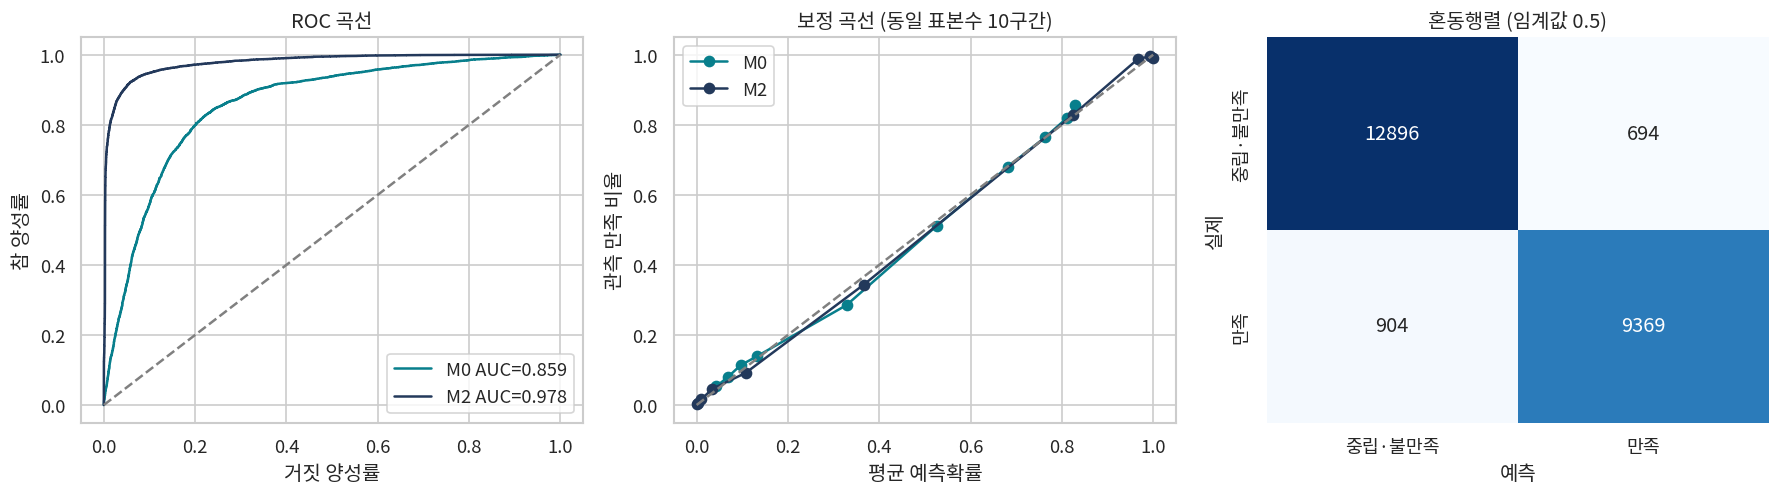

In [13]:
te=features(test,arrival_median)
performance=[];predictions={}
for name,m in final_models.items():
    p=np.asarray(m.predict(te));predictions[name]=p
    performance.append({'model':name,**metrics(te.y,p)})
# 단순 기준은 학습 만족 비율을 모든 승객에게 동일하게 예측한다.
performance.append({'model':'상수 기준',**metrics(te.y,np.repeat(tr.y.mean(),len(te)))})
performance=pd.DataFrame(performance).set_index('model')
display(performance.round(5))
p=predictions[chosen];cm=confusion_matrix(te.y,p>=.5)
print('혼동행렬 (행 실제0/1, 열 예측0/1):');print(cm)
rng=np.random.default_rng(SEED);aucs=[]
y=te.y.to_numpy()
for _ in range(500):
    idx=rng.integers(0,len(y),len(y));aucs.append(roc_auc_score(y[idx],p[idx]))
auc_ci=np.quantile(aucs,[.025,.975]);print('AUC bootstrap 95% CI:',auc_ci)
fig,axs=plt.subplots(1,3,figsize=(15,4.3))
roc_data={};cal_data={}
for name in ['M0',chosen]:
    pp=predictions[name];fpr,tpr,_=roc_curve(y,pp)
    roc_data[name]={'fpr':fpr.tolist(),'tpr':tpr.tolist()}
    axs[0].plot(fpr,tpr,label=f'{name} AUC={roc_auc_score(y,pp):.3f}')
    obs,prob=calibration_curve(y,pp,n_bins=10,strategy='quantile')
    cal_data[name]={'predicted':prob.tolist(),'observed':obs.tolist()}
    axs[1].plot(prob,obs,'o-',label=name)
axs[0].plot([0,1],[0,1],'--',color='gray');axs[0].set(xlabel='거짓 양성률',ylabel='참 양성률',title='ROC 곡선');axs[0].legend()
axs[1].plot([0,1],[0,1],'--',color='gray');axs[1].set(xlabel='평균 예측확률',ylabel='관측 만족 비율',title='보정 곡선 (동일 표본수 10구간)');axs[1].legend()
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',cbar=False,ax=axs[2],xticklabels=['중립·불만족','만족'],yticklabels=['중립·불만족','만족'])
axs[2].set(xlabel='예측',ylabel='실제',title='혼동행렬 (임계값 0.5)');plt.tight_layout();plt.show()
# 보정 절편·기울기: 이상적으로 0과 1. 이 적합은 평가용이며 예측을 재보정하지 않는다.
logit=np.log(np.clip(p,1e-8,1-1e-8)/np.clip(1-p,1e-8,1))
calmodel=sm.GLM(y,sm.add_constant(logit),family=sm.families.Binomial()).fit()
print('보정 절편/기울기:',calmodel.params)

### 테스트 성능과 시각화 해석
최종 M2의 정확도는 **93.30%**, ROC-AUC는 **0.9783**(부트스트랩 95% CI 0.9766–0.9798)이다. M0의 AUC 0.8593, M1의 0.9640보다 높다. 최종 모형 Brier는 **0.0513**, log loss는 **0.1826**로 기준모형보다 낮다.

ROC는 여러 임계값에서의 구분 능력을 나타낸다. 보정 곡선과 절편 **-0.004**, 기울기 **0.990**는 이상적 기준 0과 1에 가깝지만, 구간 평균 그림만으로 모든 하위집단의 보정이 양호하다고 할 수는 없다. 혼동행렬에서 중립·불만족 694건을 만족으로 예측했고, 만족 904건을 놓쳤다. 정밀도는 **93.10%**, 재현율은 **91.20%**이다. 과거 탐색된 동일 출처 분할 평가라는 한계가 남는다.

**보고서의 주 결론은 이 성능 순위가 아니라 본문의 조건부 관련성과 해석의 한계이다.**

In [14]:
sens_te=features(fill_services(test_all),train_all.arrival.median())
sens_p=sens.predict(sens_te)
sens_metrics=metrics(sens_te.y,sens_p)
print('전체 자료 대체 사양의 보조 예측 성능:',sens_metrics)

전체 자료 대체 사양의 보조 예측 성능: {'AUC': 0.9737513772979345, 'accuracy': 0.9226978749615029, 'precision': 0.9223231142677335, 'recall': 0.8996755239849162, 'F1': 0.9108585634378052, 'Brier': 0.05840357949653676, 'logloss': 0.20332727668972853}


In [15]:
# 분석 결과를 PPT와 대조하기 위한 중간 산출물. 제출 노트북 실행에는 사전 생성 파일이 필요 없다.
RESULT_DIR=Path.cwd()/'analysis_results';RESULT_DIR.mkdir(exist_ok=True)
def records(df):return json.loads(df.to_json(orient='records',force_ascii=False))
result={'seed':SEED,'versions':versions,'hashes':source_hashes,'chosen':chosen,
 'flow':records(flow),'selection':records(selection.reset_index()),
 'validation':records(validation.reset_index()),'fit_summary':records(fit_summary),
 'contrast':records(contrast),'full_coef':records(full_coef.reset_index(names='term')),
 'performance':records(performance.reset_index()),'confusion_matrix':cm.tolist(),
 'auc_ci':auc_ci.tolist(),'calibration':cal_data,'roc':roc_data,
 'calibration_intercept':float(calmodel.params[0]),'calibration_slope':float(calmodel.params[1]),
 'vif':records(vif),'condition':condition,'max_cook':max_cook,'max_hat':max_hat,
 'lr':float(lr),'lr_df':lr_df,'lr_p':float(stats.chi2.sf(lr,lr_df)),
 'correlation_pairs':corr_pairs,'sensitivity':records(sensitivity),'sensitivity_metrics':sens_metrics,
 'zero_counts':records(zero_table),'arrival_median':arrival_median,'service_medians':service_medians,
 'crude':records(crude),'no_wifi':records(no_wifi_table),
 'rating_counts':{s:t.reset_index().to_dict(orient='records') for s,t in rating_counts.items()},
 'group_rates':{k:records(v.reset_index()) for k,v in rates.items()},
 'service_distributions':{s:records(train.groupby(s).y.agg(['count','mean']).reset_index()) for s in SKEYS}}
(RESULT_DIR/'results.json').write_text(json.dumps(result,ensure_ascii=False,indent=2),encoding='utf-8')
contrast.to_csv(RESULT_DIR/'service_contrasts.csv',index=False,encoding='utf-8-sig')
full_coef.to_csv(RESULT_DIR/'full_coefficients.csv',encoding='utf-8-sig')
print('분석 완료:',chosen,'학습 n=',len(tr),'테스트 n=',len(te))

분석 완료: M2 학습 n= 95704 테스트 n= 23863


### C. 참고자료와 재현 정보

참고자료 (접근일 2026-10-29)
1. Kaggle, teejmahal20. [Airline Passenger Satisfaction](https://www.kaggle.com/datasets/teejmahal20/airline-passenger-satisfaction). 데이터 출처와 변수 설명. 와이파이 0=Not Applicable. 분류용 정리 자료라는 설명을 포함한다.
2. statsmodels. [Generalized Linear Models](https://www.statsmodels.org/stable/glm.html). 이항 로짓 회귀 구현.
3. statsmodels. [Multipletests](https://www.statsmodels.org/stable/generated/statsmodels.stats.multitest.multipletests.html). Benjamini–Hochberg 보정.
4. scikit-learn. [Probability calibration](https://scikit-learn.org/stable/modules/calibration.html). 보정 곡선과 확률 예측 오차의 구별.
5. scikit-learn. [Model evaluation](https://scikit-learn.org/stable/modules/model_evaluation.html). ROC-AUC, log loss 등 평가 지표.